# ✈️🏅 Exploratory Data Analysis: NYC Flights & 120 Years of Olympic History

**Goal:** practise a full exploratory data analysis (EDA) workflow on two real datasets:

1. **NYC Flights 2013**: all 336,776 flights departing New York City airports in 2013. *When and why are flights delayed?*
2. **Olympic History (1896–2016)**: 271,116 athlete entries. *Which countries dominate, and how has participation changed?*

**Workflow:** load → inspect → clean → analyse → visualise → summarise insights.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from nycflights13 import flights

sns.set_theme(style="whitegrid")
import os
os.makedirs("images", exist_ok=True)
def savefig(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

## Part 1: NYC Flights 2013
### 1.1 Inspect the data

In [2]:
df = flights.copy()
print("Shape:", df.shape)
df.head()

Shape: (336776, 19)


,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01T10:00:00Z
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01T10:00:00Z
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01T10:00:00Z
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01T10:00:00Z
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01T11:00:00Z


In [3]:
# Missing values per column: flights with no departure time were cancelled
df.isna().sum().sort_values(ascending=False).head(8)

arr_delay    9430
air_time     9430
arr_time     8713
dep_time     8255
dep_delay    8255
tailnum      2512
year            0
day             0
dtype: int64

### 1.2 Clean
Rows without `dep_delay` are cancelled flights. We count them, then drop them for delay analysis.

In [4]:
cancelled = df["dep_delay"].isna().sum()
print(f"Cancelled flights: {cancelled:,} ({cancelled/len(df):.1%})")

clean = df.dropna(subset=["dep_delay", "arr_delay"]).copy()
clean["date"] = pd.to_datetime(clean[["year", "month", "day"]])
clean["delayed_15"] = clean["dep_delay"] > 15   # standard industry definition
print("Rows after cleaning:", len(clean))
clean[["dep_delay", "arr_delay", "distance", "air_time"]].describe().round(1)

Cancelled flights: 8,255 (2.5%)


Rows after cleaning: 327346


,dep_delay,arr_delay,distance,air_time
count,327346.0,327346.0,327346.0,327346.0
mean,12.6,6.9,1048.4,150.7
std,40.1,44.6,735.9,93.7
min,-43.0,-86.0,80.0,20.0
25%,-5.0,-17.0,509.0,82.0
50%,-2.0,-5.0,888.0,129.0
75%,11.0,14.0,1389.0,192.0
max,1301.0,1272.0,4983.0,695.0


### 1.3 Which months have the worst delays?

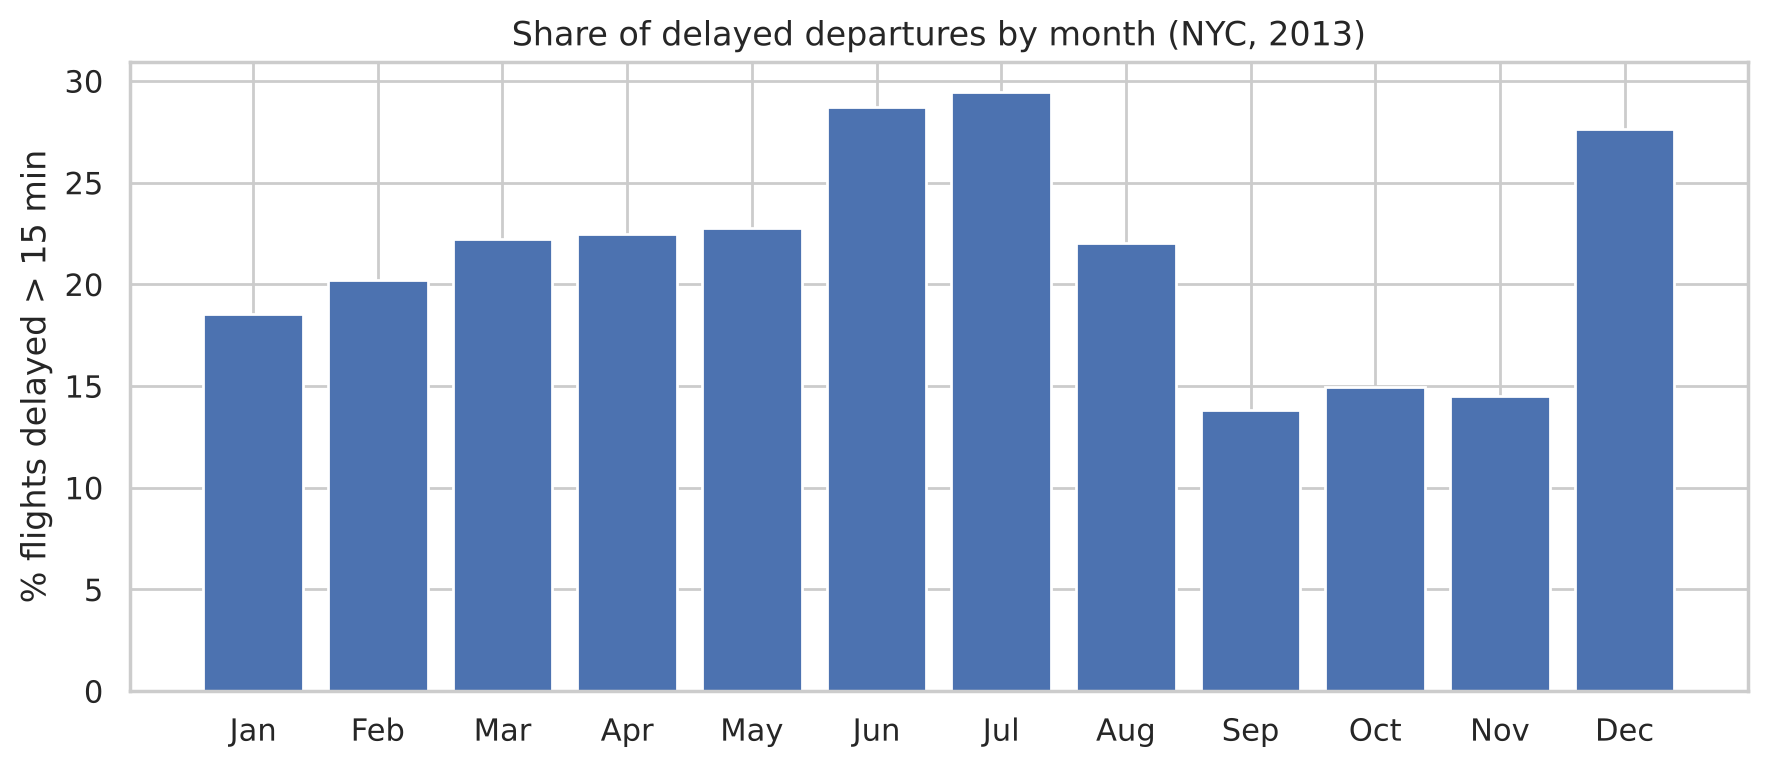

,avg_delay,pct_delayed
month,,
1,9.99,0.19
2,10.76,0.20
3,13.16,0.22
4,13.85,0.22
5,12.89,0.23
6,20.73,0.29
7,21.52,0.29
8,12.57,0.22
9,6.63,0.14


In [5]:
monthly = clean.groupby("month").agg(avg_delay=("dep_delay", "mean"),
                                     pct_delayed=("delayed_15", "mean"))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(monthly.index, monthly["pct_delayed"] * 100, color="#4C72B0")
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("% flights delayed > 15 min")
ax.set_title("Share of delayed departures by month (NYC, 2013)")
savefig("delays_by_month")
monthly.round(2)

**Insight:** summer (June–July) and December are the worst months: thunderstorms and holiday traffic. Autumn (Sep–Nov) is the most reliable.

### 1.4 Does the time of day matter?

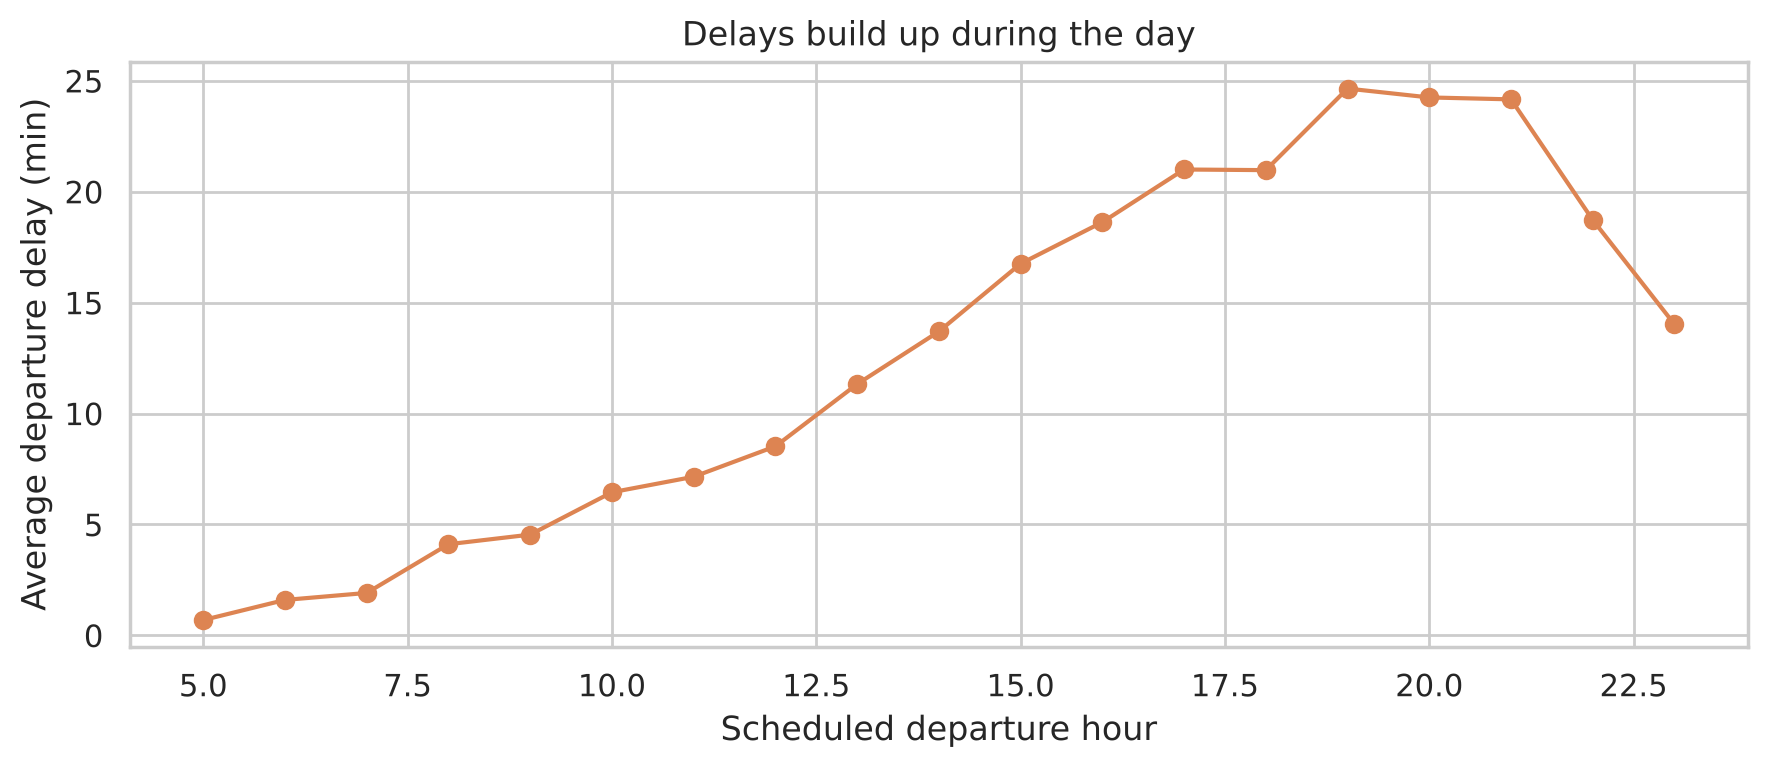

In [6]:
hourly = clean[(clean["hour"] >= 5) & (clean["hour"] <= 23)].groupby("hour")["dep_delay"].mean()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hourly.index, hourly.values, marker="o", color="#DD8452")
ax.set_xlabel("Scheduled departure hour"); ax.set_ylabel("Average departure delay (min)")
ax.set_title("Delays build up during the day")
savefig("delay_by_hour")

**Insight:** early-morning flights leave almost on time; delays accumulate through the day and peak in the evening (knock-on effects). *Tip for travellers: book the first flight.*

### 1.5 Which airlines are most punctual?

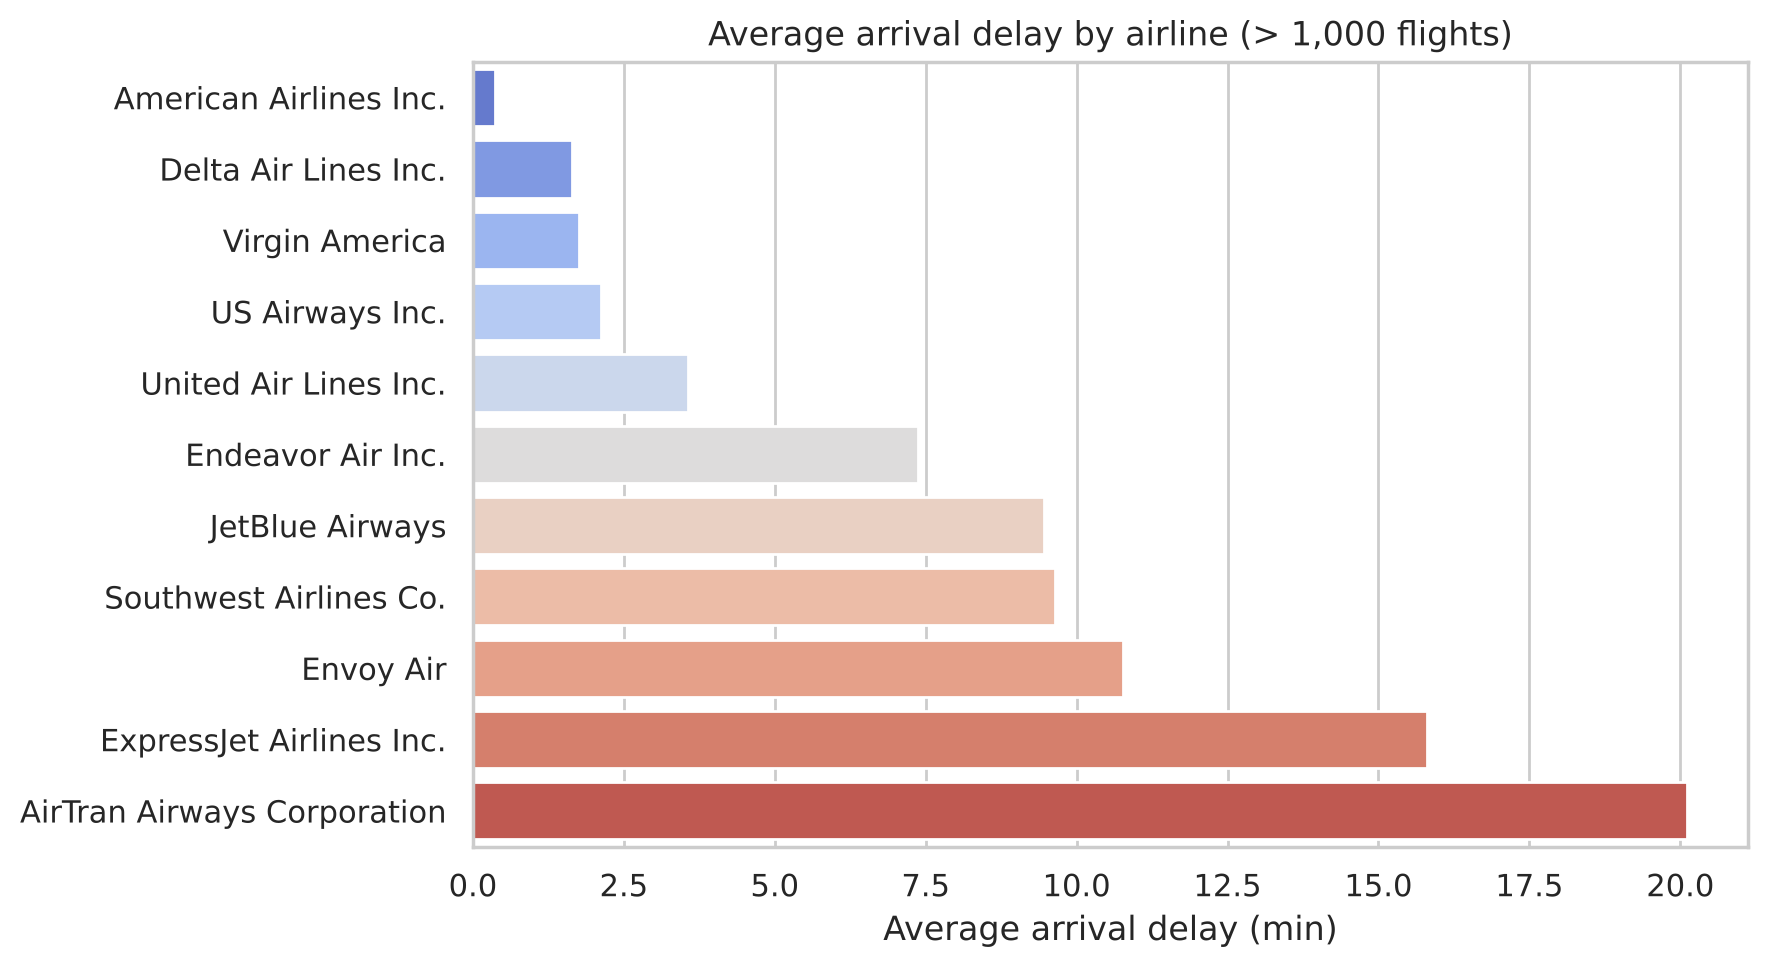

,carrier,flights,avg_arr_delay,name
1,AA,31947,0.4,American Airlines Inc.
3,DL,47658,1.6,Delta Air Lines Inc.
9,VX,5116,1.8,Virgin America
8,US,19831,2.1,US Airways Inc.
7,UA,57782,3.6,United Air Lines Inc.
0,9E,17294,7.4,Endeavor Air Inc.
2,B6,54049,9.5,JetBlue Airways
10,WN,12044,9.6,Southwest Airlines Co.
6,MQ,25037,10.8,Envoy Air
4,EV,51108,15.8,ExpressJet Airlines Inc.


In [7]:
from nycflights13 import airlines
carrier = (clean.groupby("carrier")
           .agg(flights=("flight", "count"), avg_arr_delay=("arr_delay", "mean"))
           .query("flights > 1000")
           .merge(airlines, on="carrier")
           .sort_values("avg_arr_delay"))
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=carrier, y="name", x="avg_arr_delay", palette="coolwarm", ax=ax, hue="name", legend=False)
ax.set_xlabel("Average arrival delay (min)"); ax.set_ylabel("")
ax.set_title("Average arrival delay by airline (> 1,000 flights)")
savefig("delay_by_airline")
carrier.round(1)

### 1.6 Are departure and arrival delays related?

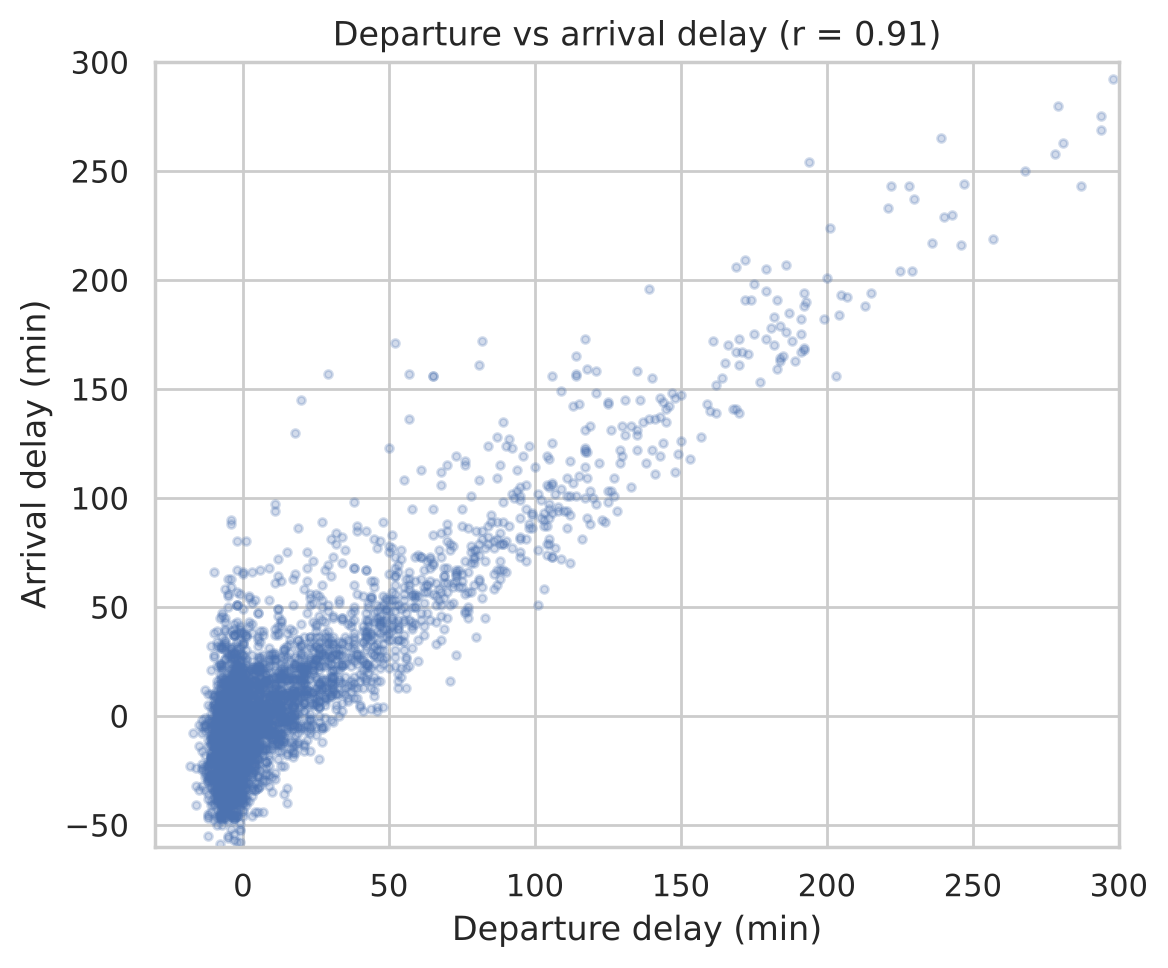

In [8]:
sample = clean.sample(5000, random_state=42)
corr = clean["dep_delay"].corr(clean["arr_delay"])
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(sample["dep_delay"], sample["arr_delay"], alpha=0.25, s=8)
ax.set_xlim(-30, 300); ax.set_ylim(-60, 300)
ax.set_xlabel("Departure delay (min)"); ax.set_ylabel("Arrival delay (min)")
ax.set_title(f"Departure vs arrival delay (r = {corr:.2f})")
savefig("dep_vs_arr_delay")

**Insight:** a very strong linear relationship (r ≈ 0.92). Planes rarely "make up" much time in the air.

## Part 2: 120 Years of Olympic History
### 2.1 Load and inspect

In [9]:
URL = "https://raw.githubusercontent.com/rgriff23/Olympic_history/master/data/athlete_events.csv"
oly = pd.read_csv(URL)
print("Shape:", oly.shape)
oly.head()

Shape: (271116, 15)


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [10]:
oly.isna().sum()

ID             0
Name           0
Sex            0
Age         9474
Height     60171
Weight     62875
Team           0
NOC            0
Games          0
Year           0
Season         0
City           0
Sport          0
Event          0
Medal     231333
dtype: int64

### 2.2 Clean
`Medal` is missing when the athlete did not win, which is not an error. For medal counts we must also remember that a **team** gold (e.g. football) gives one medal to every player, so we count unique (event, year, team, medal) combinations.

In [11]:
oly["Medal"] = oly["Medal"].fillna("None")
medals = (oly[oly["Medal"] != "None"]
          .drop_duplicates(subset=["Year", "Season", "Event", "NOC", "Medal"]))
print("Unique medals awarded:", len(medals))

Unique medals awarded: 18905


### 2.3 Top 10 countries by Summer Olympic medals

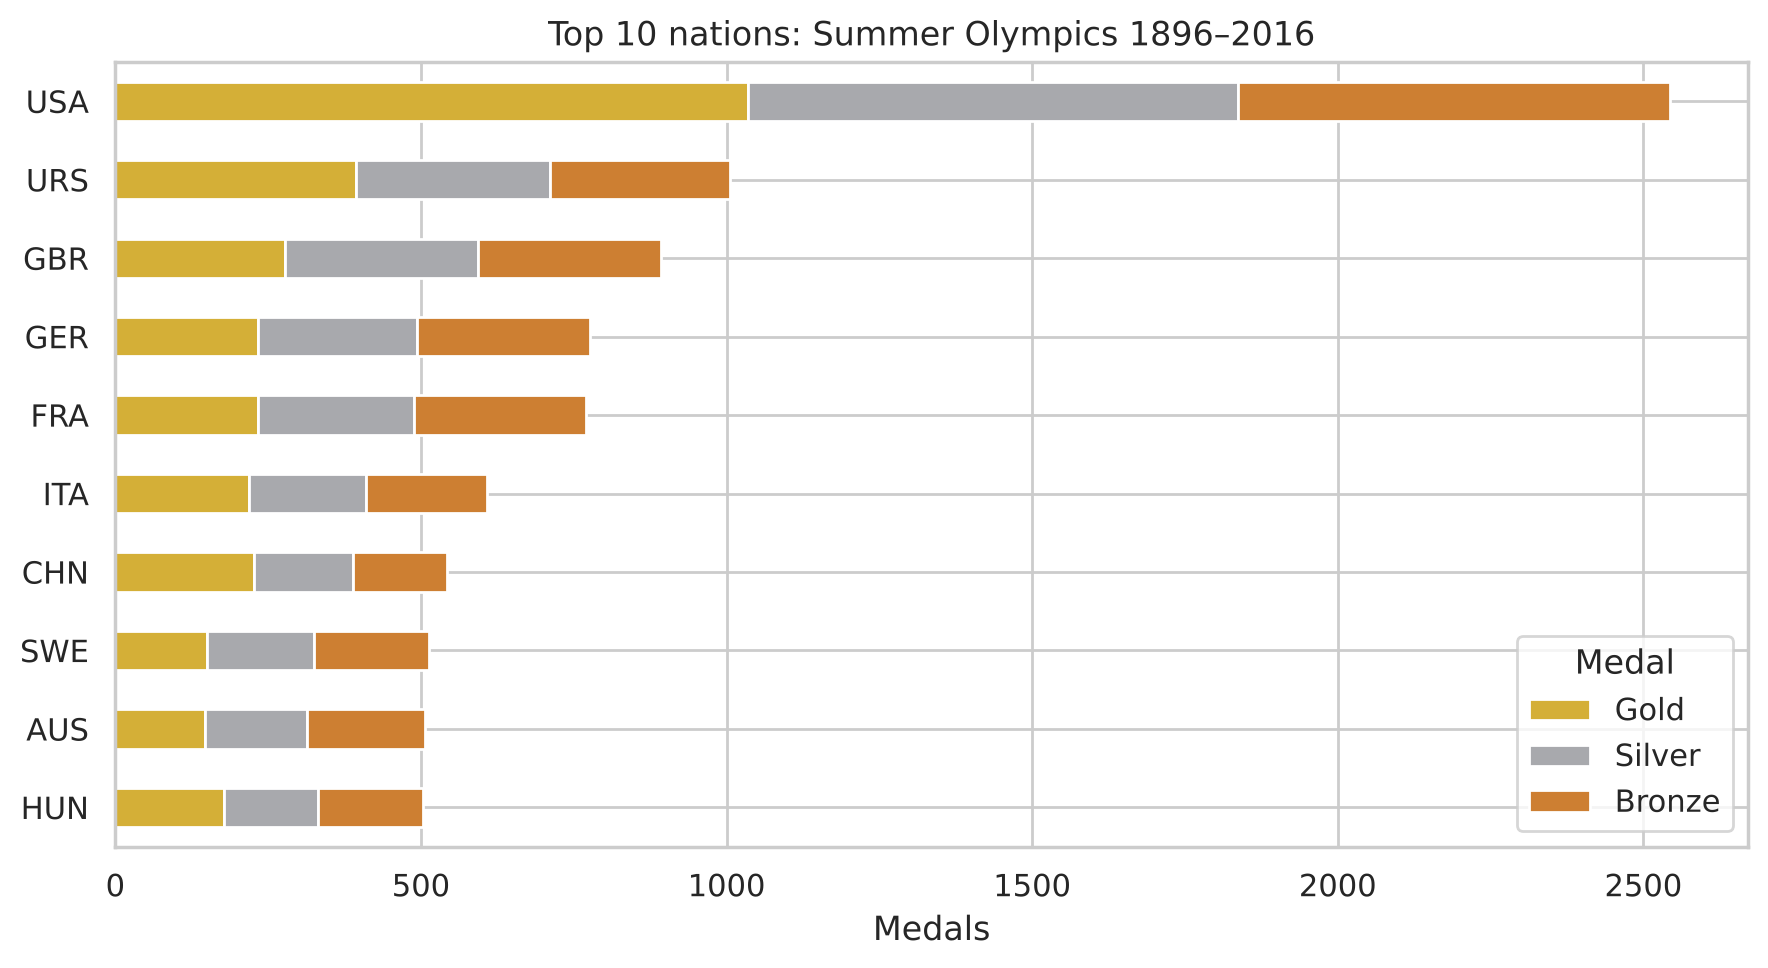

Medal,Gold,Silver,Bronze,Total
NOC,,,,
USA,1035,802,707,2544
URS,394,317,294,1005
GBR,278,316,298,892
GER,233,261,282,776
FRA,233,255,282,770
ITA,219,191,198,608
CHN,227,162,153,542
SWE,150,175,188,513
AUS,147,167,192,506


In [12]:
top = (medals[medals["Season"] == "Summer"]
       .groupby(["NOC", "Medal"]).size().unstack(fill_value=0)[["Gold", "Silver", "Bronze"]])
top["Total"] = top.sum(axis=1)
top10 = top.sort_values("Total", ascending=False).head(10)
top10[["Gold", "Silver", "Bronze"]].plot(kind="barh", stacked=True, figsize=(9, 5),
                                         color=["#D4AF37", "#A8A9AD", "#CD7F32"])
plt.gca().invert_yaxis(); plt.xlabel("Medals"); plt.ylabel("")
plt.title("Top 10 nations: Summer Olympics 1896–2016")
savefig("top10_medals")
top10

### 2.4 How has participation changed?

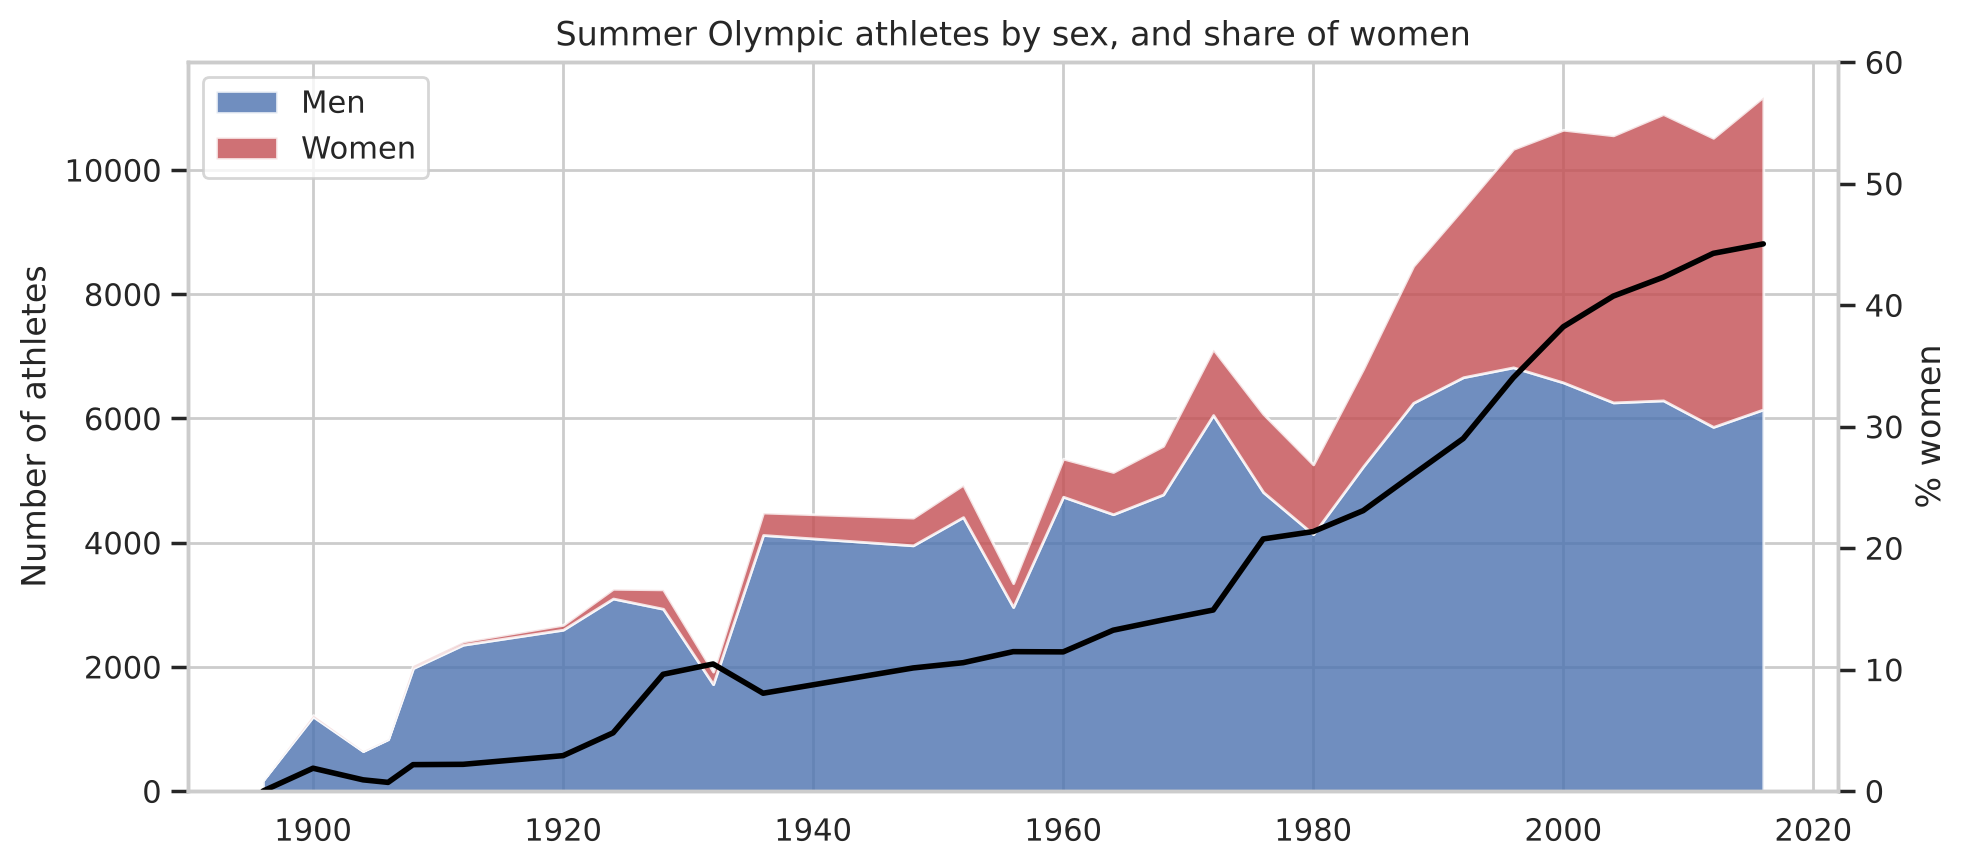

Sex,F,M,female_share
Year,,,
2000,4068,6579,38.207946
2004,4300,6257,40.731268
2008,4609,6290,42.288283
2012,4654,5863,44.252163
2016,5034,6145,45.030861


In [13]:
summer = oly[oly["Season"] == "Summer"]
part = summer.groupby(["Year", "Sex"])["ID"].nunique().unstack(fill_value=0)
part["female_share"] = part["F"] / (part["F"] + part["M"]) * 100

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.stackplot(part.index, part["M"], part["F"], labels=["Men", "Women"], colors=["#4C72B0", "#C44E52"], alpha=.8)
ax1.set_ylabel("Number of athletes"); ax1.legend(loc="upper left")
ax2 = ax1.twinx(); ax2.plot(part.index, part["female_share"], color="black", lw=2, label="% women")
ax2.set_ylabel("% women"); ax2.set_ylim(0, 60); ax2.grid(False)
ax1.set_title("Summer Olympic athletes by sex, and share of women")
savefig("participation_by_sex")
part.tail()

**Insight:** women made up under 5 % of athletes until 1924 and about 45 % by 2016. The dips in total athletes in 1932, 1956, 1976 and 1980 match historical events (the Great Depression, the long trip to Melbourne, and the Montreal and Moscow boycotts).

### 2.5 Age of medal winners by sport

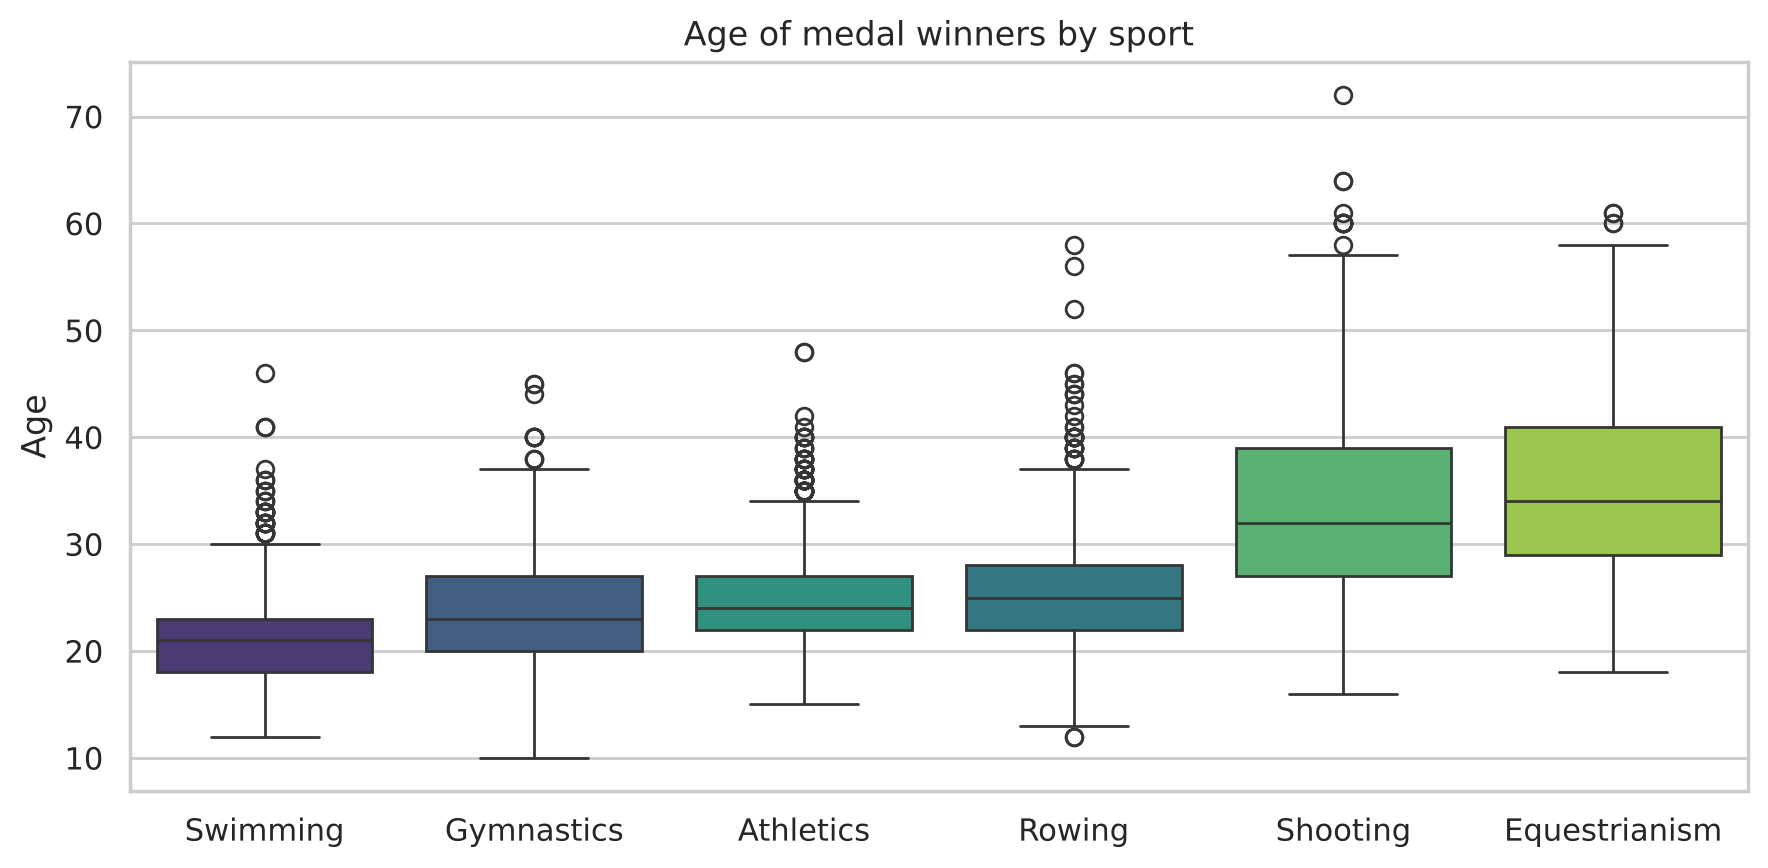

Sport
Swimming         21.0
Gymnastics       23.0
Athletics        24.0
Rowing           25.0
Shooting         32.0
Equestrianism    34.0
Name: Age, dtype: float64

In [14]:
sports = ["Gymnastics", "Swimming", "Athletics", "Rowing", "Equestrianism", "Shooting"]
sub = oly[(oly["Medal"] != "None") & (oly["Sport"].isin(sports))].dropna(subset=["Age"])
order = sub.groupby("Sport")["Age"].median().sort_values().index
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=sub, x="Sport", y="Age", order=order, hue="Sport", palette="viridis", legend=False)
plt.title("Age of medal winners by sport"); plt.xlabel("")
savefig("age_by_sport")
sub.groupby("Sport")["Age"].median().sort_values()

## Summary of key insights

| Dataset | Finding |
|---|---|
| Flights | 2.5 % of flights were cancelled; in June, July and December ~29 % of flights leave > 15 min late, vs ~14 % in autumn |
| Flights | Delays grow during the day: early-morning flights are the most punctual |
| Flights | Departure delay almost fully predicts arrival delay (r ≈ 0.92) |
| Olympics | The USA leads the all-time Summer medal table (2,544 medals), more than double the Soviet Union in 2nd |
| Olympics | Women's participation grew from < 5 % to ~45 % of athletes |
| Olympics | Swimmers win youngest (median age 21), equestrians and shooters oldest (32–34) |

**Skills shown:** data loading, missing-value handling, groupby/aggregation, merging tables, avoiding a double-counting trap (team medals), and clear visualisation.